<img src="https://www.nvidia.com/content/dam/en-zz/Solutions/about-nvidia/logo-and-brand/01-nvidia-logo-vert-500x200-2c50-d.png" width="160">

# Caja Clara · Detector de productos con NVIDIA TAO Toolkit
### Hackathon NVIDIA Oaxaca 2026 · Economía Digital

**Caja Clara** es una app para micronegocios: la persona toma **una foto** de lo que vende, nuestro detector reconoce los productos, ella **revisa y corrige**, cobra en efectivo o por transferencia (DiMo/CoDi, *simulado*) y la venta queda guardada.

Esta libreta documenta **de punta a punta** el entrenamiento del componente de visión, tal como lo trabajamos en los cursos del NVIDIA Deep Learning Institute.

## Objetivos
Al terminar esta libreta habremos:
1. Verificado el entorno de entrenamiento (GPU, TAO Toolkit, NGC).
2. Explorado el dataset: fuentes, licencias, distribución por clase y ejemplos con sus cajas.
3. Ajustado (*fine-tuning*) un detector **DINO** preentrenado en COCO para nuestras 7 clases.
4. Evaluado el modelo con datos de prueba reservados (mAP) y revisado aciertos y errores.
5. Exportado el modelo a **ONNX** y optimizado con **TensorRT**.
6. Generado los artefactos y registros que piden las bases (sección 14C).

## Contenido
1. [Entorno](#1)
2. [Datos](#2)
3. [Modelo base](#3)
4. [Configuración del experimento](#4)
5. [Entrenamiento](#5)
6. [Evaluación](#6)
7. [Inferencia: aciertos y errores](#7)
8. [Exportación y TensorRT](#8)
9. [Artefactos y verificación](#9)
10. [Resultados, limitaciones y declaración de IA](#10)

<a id="1"></a>
## 1. Entorno
Usamos el entorno GPU de los cursos DLI (cuenta NVIDIA Developer) con el **launcher de TAO**, que ejecuta cada tarea dentro del contenedor oficial `nvcr.io/nvidia/tao/tao-toolkit:5.5.0-pyt`.

Las rutas del **host** (`/dli/task/caja-clara`) se montan dentro del contenedor como `/workspace/caja-clara` (ver `~/.tao_mounts.json`).

In [1]:
import os, json, glob, hashlib, re, subprocess, datetime
HOST = "/dli/task/caja-clara"           # ruta en este entorno
CONT = "/workspace/caja-clara"          # misma carpeta vista desde el contenedor de TAO
os.chdir(HOST)
def a_cont(p): return p.replace(HOST, CONT)
def a_host(p): return p.replace(CONT, HOST)
def bitacora(msg):
    linea = f"{msg} — {datetime.datetime.utcnow():%Y-%m-%d %H:%M:%S} UTC"
    with open("logs/bitacora.txt", "a") as f: f.write(linea + "\n")
    print(linea)
print("Carpeta de trabajo:", os.getcwd())

Carpeta de trabajo: /dli/task/caja-clara


In [2]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
!tao info 2>/dev/null | grep -E "toolkit_version|published"
!cat ~/.tao_mounts.json

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 545.23.08
toolkit_version: 5.5.0
published_date: 08/26/2024
{
  "Mounts": [
    {"source": "/dli/task/caja-clara", "destination": "/workspace/caja-clara"}
  ],
  "DockerOptions": {"shm_size": "8G"}
}


In [3]:
# Librerías para gráficas e imágenes (si faltan, se instalan desde PyPI)
try:
    import matplotlib; from PIL import Image
except ImportError:
    !pip install -q --index-url https://pypi.org/simple matplotlib pillow
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image
%matplotlib inline
print("matplotlib", matplotlib.__version__)

matplotlib 3.10.0


<a id="2"></a>
## 2. Datos
### 2.1 Fuentes y licencias
Combinamos **datos públicos** (Roboflow Universe, licencia CC BY 4.0) con **fotos propias** tomadas durante el hackathon. Las bases (sección 10) permiten datasets públicos identificando su procedencia y licencia.

| Conjunto | Origen | Uso |
|---|---|---|
| Entrenamiento | Datos públicos (y en v2 también fotos propias de otras sesiones) | Actualizar los parámetros |
| Validación | v1: públicos · v2: fotos propias (sesiones s01–s02) | Elegir configuración y vigilar el sobreajuste |
| Prueba | v1: públicos · v2: fotos propias (sesiones s03–s05) | Evaluar al final con ejemplos reservados |

In [4]:
print(open("datos/FUENTES.txt").read())

ProductosOXXO_V02 v3 - https://universe.roboflow.com/ipsum/productosoxxo_v02 - CC BY 4.0
Dataset Mercado v1 - https://universe.roboflow.com/fundamentosia/dataset-mercado - CC BY 4.0



### 2.2 Preparación: sin fugas entre conjuntos
El script `preparar_datos.py`:
- deja solo nuestras 7 clases y las renumera de 1 a 7,
- mantiene juntas las **variantes** de una misma imagen (aumentos de Roboflow `*.rf.*`), para que nunca queden en conjuntos distintos,
- separa las fotos propias **por sesión** (`sNN_`),
- descarta duplicados exactos entre conjuntos (hash SHA-1).

> Bases, sección 7: *"No deberán colocarse imágenes duplicadas ni versiones de la misma imagen en conjuntos distintos."*

In [5]:
# Ejecutar solo si aún no existe datos/final (v1: solo públicos)
if not os.path.exists("datos/final/train/annotations.json"):
    !python3 preparar_datos.py --publicos datos/roboflow/oxxo datos/roboflow/mercado | tee logs/preparar_datos.log
dist = json.load(open("logs/distribucion_datos.json"))
CLASES = dist["clases"]
print("Clases:", CLASES, "| num_classes para el spec:", dist["num_classes_para_spec"])
for c, v in dist["conjuntos"].items():
    print(f"{c:6s} imágenes={v['imagenes']:5d}  objetos={v['objetos']:5d}")

Clases: ['chokis', 'coca_cola', 'doritos', 'gansito', 'panditas', 'sabritas', 'skittles'] | num_classes para el spec: 8
train  imágenes=  819  objetos=  819
val    imágenes=   97  objetos=   98
test   imágenes=  106  objetos=  106


### 2.3 Distribución por clase

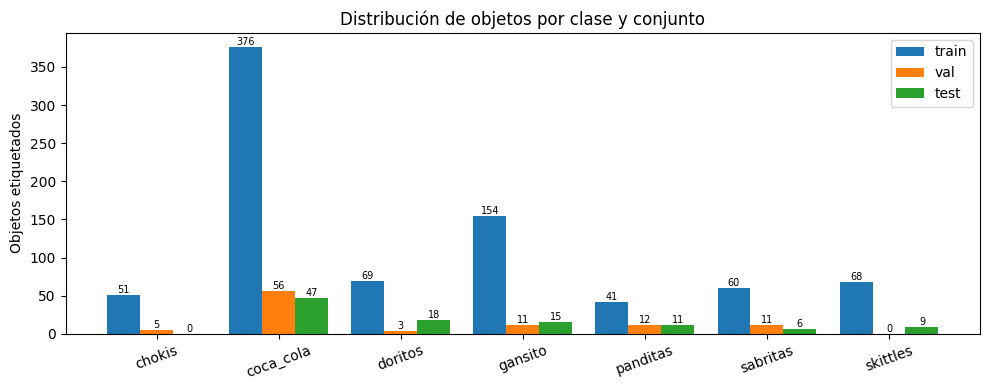

In [6]:
import numpy as np
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(CLASES)); w = 0.27
for i, conj in enumerate(["train", "val", "test"]):
    vals = [dist["conjuntos"][conj]["por_clase"][c] for c in CLASES]
    b = ax.bar(x + (i - 1) * w, vals, w, label=conj)
    ax.bar_label(b, fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(CLASES, rotation=20)
ax.set_ylabel("Objetos etiquetados"); ax.set_title("Distribución de objetos por clase y conjunto")
ax.legend(); plt.tight_layout(); plt.savefig("logs/distribucion_clases.png", dpi=120); plt.show()

### 2.4 Ejemplos con sus etiquetas
Así se ven las imágenes y las cajas (*bounding boxes*) que aprende el modelo.

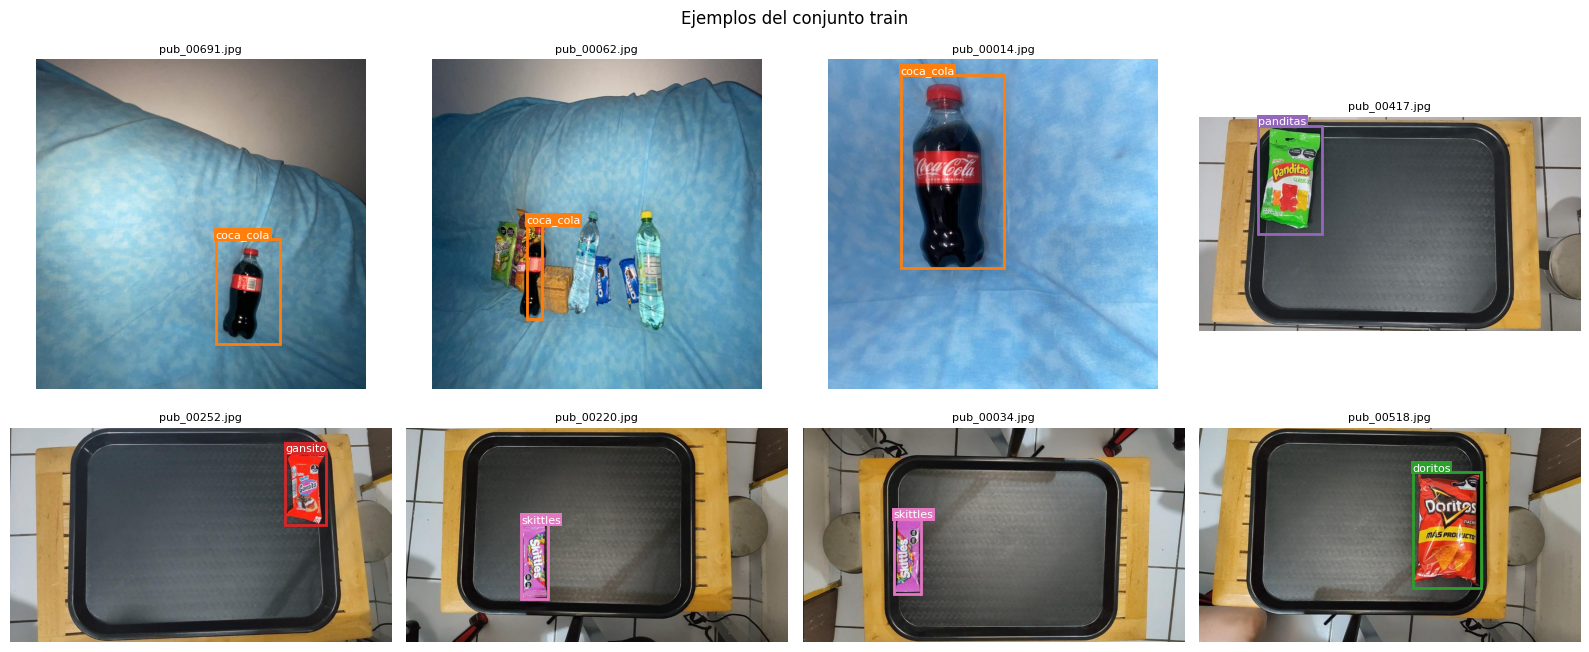

In [7]:
COLORES = plt.cm.tab10.colors
def carga_coco(conj):
    d = json.load(open(f"datos/final/{conj}/annotations.json"))
    por_img = {}
    for a in d["annotations"]: por_img.setdefault(a["image_id"], []).append(a)
    return d, por_img

def muestra(conj="train", n=8, semilla=0, columnas=4):
    d, por_img = carga_coco(conj)
    rng = np.random.default_rng(semilla)
    imgs = rng.choice(d["images"], size=min(n, len(d["images"])), replace=False)
    filas = int(np.ceil(len(imgs) / columnas))
    fig, axs = plt.subplots(filas, columnas, figsize=(4 * columnas, 3.6 * filas))
    for ax in np.array(axs).ravel(): ax.axis("off")
    for ax, im in zip(np.array(axs).ravel(), imgs):
        ax.imshow(Image.open(f"datos/final/{conj}/images/{im['file_name']}").convert("RGB"))
        for a in por_img.get(im["id"], []):
            x0, y0, bw, bh = a["bbox"]; k = a["category_id"] - 1
            ax.add_patch(patches.Rectangle((x0, y0), bw, bh, fill=False, lw=2, color=COLORES[k]))
            ax.text(x0, y0 - 3, CLASES[k], color="white", fontsize=8, bbox=dict(facecolor=COLORES[k], pad=1, lw=0))
        ax.set_title(im["file_name"], fontsize=8)
    plt.suptitle(f"Ejemplos del conjunto {conj}"); plt.tight_layout(); plt.show()

muestra("train", n=8)

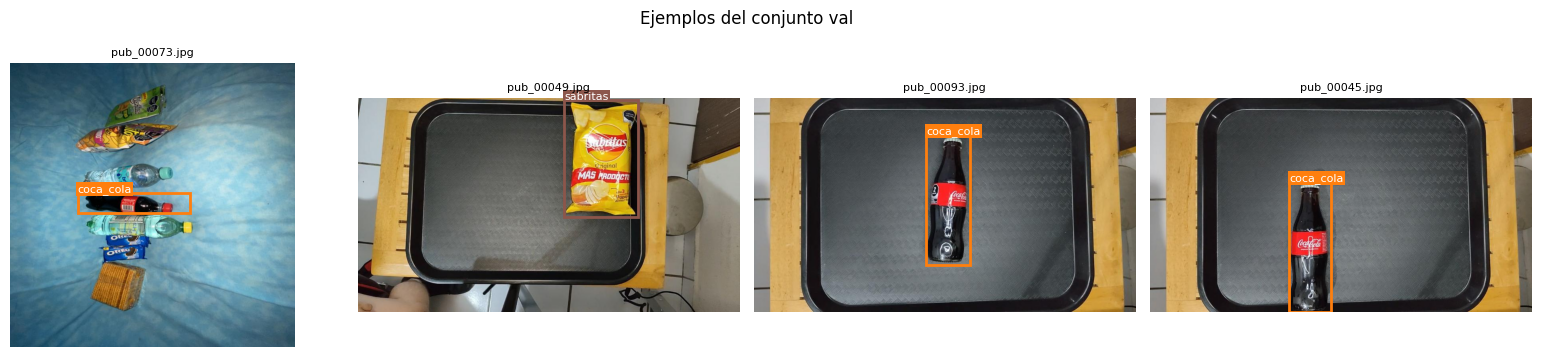

In [8]:
muestra("val", n=4, semilla=1)

### 2.5 Tamaños de imagen y verificación de fugas

In [9]:
tam = []
for conj in ["train", "val", "test"]:
    d, _ = carga_coco(conj)
    tam += [(conj, im["width"], im["height"]) for im in d["images"]]
anchos = [t[1] for t in tam]; altos = [t[2] for t in tam]
print(f"Ancho: min {min(anchos)}, mediana {int(np.median(anchos))}, max {max(anchos)}")
print(f"Alto : min {min(altos)}, mediana {int(np.median(altos))}, max {max(altos)}")

def sha1(p): return hashlib.sha1(open(p, "rb").read()).hexdigest()
hashes = {c: {sha1(p) for p in glob.glob(f"datos/final/{c}/images/*")} for c in ["train", "val", "test"]}
print("Duplicados train∩val :", len(hashes["train"] & hashes["val"]))
print("Duplicados train∩test:", len(hashes["train"] & hashes["test"]))
print("Duplicados val∩test  :", len(hashes["val"] & hashes["test"]))

Ancho: min 640, mediana 960, max 960
Alto : min 540, mediana 540, max 640
Duplicados train∩val : 0
Duplicados train∩test: 0
Duplicados val∩test  : 0


<a id="3"></a>
## 3. Modelo base
| Campo | Valor |
|---|---|
| Arquitectura | **DINO** (*DETR with Improved deNoising anchOr boxes*), detector basado en transformers |
| Backbone | ResNet-50 |
| Preentrenamiento | COCO (80 clases) |
| Procedencia | NGC: `nvidia/tao/pretrained_dino_coco:dino_resnet_50_trainable_v1.0` |
| Licencia | Modelo de TAO Toolkit en NGC (términos de NVIDIA TAO) |

Partimos de un detector que **ya sabe localizar objetos** y lo ajustamos (*transfer learning*) a nuestras clases. Las bases (sección 7) permiten partir de un modelo preentrenado: *"No se exige entrenar desde cero."*

In [10]:
base = glob.glob("modelos_base/**/*.pth", recursive=True)[0]
print(base, f"{os.path.getsize(base)/1e6:.1f} MB")
print("sha256:", hashlib.sha256(open(base, "rb").read()).hexdigest())

modelos_base/pretrained_dino_coco_vdino_resnet_50_trainable_v1.0/dino_resnet50_ep12.pth 568.8 MB
sha256: 7a391fb84a18714b60258becdb512594ec54faff5dccbf17ca53c5d902137512


<a id="4"></a>
## 4. Configuración del experimento
El spec parte de la configuración por defecto de DINO en TAO 5.5 (`nvidia_tao_pytorch.cv.dino`) con estos ajustes para la **Tesla T4 (16 GB)**:

| Parámetro | Por defecto | Nuestro valor | Motivo |
|---|---|---|---|
| `batch_size` | 4 | 2 | Cabe en 16 GB |
| Tamaño de imagen | 480–800 (máx. 1333) | 480–640 (máx. 800) | ~3× más rápido |
| `precision` | fp32 | fp16 | Tensor Cores de la T4 |
| `num_epochs` / `lr_steps` | 10 / [11] | 12 / [9] | Ajuste fino corto |
| `num_classes` | 91 | 8 | 7 clases + 1 |

In [11]:
SPEC = f"{HOST}/specs/train.yaml"
print(open(SPEC).read())

# Caja Clara - DINO (TAO 5.5) - ajustado a Tesla T4 16GB
# Basado en la config por defecto de nvidia_tao_pytorch.cv.dino (TAO 5.5.0)
results_dir: /workspace/caja-clara/resultados/dino_v1
wandb:
  enable: false
model:
  backbone: resnet_50
  train_backbone: true
  num_feature_levels: 4
  num_queries: 300
  num_select: 100
  dec_layers: 6
  enc_layers: 6
  dropout_ratio: 0.0
dataset:
  train_data_sources:
    - image_dir: /workspace/caja-clara/datos/final/train/images
      json_file: /workspace/caja-clara/datos/final/train/annotations.json
  val_data_sources:
    - image_dir: /workspace/caja-clara/datos/final/val/images
      json_file: /workspace/caja-clara/datos/final/val/annotations.json
  num_classes: 8
  batch_size: 2
  workers: 4
  augmentation:
    scales: [480, 512, 544, 576, 608, 640]
    train_random_resize: [400, 500, 600]
    train_random_crop_min: 384
    train_random_crop_max: 600
    random_resize_max_size: 800
    test_random_resize: 640
    horizontal_flip_prob: 0.5
   

<a id="5"></a>
## 5. Entrenamiento
El entrenamiento corre **en el servidor GPU** con el launcher de TAO. Todo se guarda en `resultados/dino_v1/` y el log completo en `logs/`, como evidencia (bases, secciones 9 y 14C).

> Si el entrenamiento ya se lanzó desde la terminal, **no vuelvan a correr la siguiente celda**: pasen directo al monitoreo.

In [12]:
RES = f"{HOST}/resultados/dino_v1"
ckpts = sorted(glob.glob(f"{RES}/train/*.pth"))
if ckpts:
    print("Ya hay checkpoints, no se relanza:", [os.path.basename(c) for c in ckpts][-3:])
else:
    bitacora("Inicio entrenamiento DINO v1 desde la libreta")
    !nohup tao model dino train -e {a_cont(SPEC)} > logs/entrenamiento_dino_v1.log 2>&1 &

Ya hay checkpoints, no se relanza: ['model_epoch_009.pth', 'model_epoch_010.pth', 'model_epoch_011.pth']


### 5.1 Monitoreo

In [13]:
!tail -n 15 logs/entrenamiento_dino_v1.log
!nvidia-smi --query-gpu=utilization.gpu,memory.used,memory.total --format=csv

Validation DataLoader 0: 100%|██████████| 49/49 [00:09<00:00,  5.38it/s] Validation mAP : 0.9114595631696899


 Validation mAP50 : 0.9966996699669967



                                                                        
Epoch 11: 100%|██████████| 409/409 [04:02<00:00,  1.69it/s, v_num=1, train_loss_step=4.490, lr=2e-5, val_loss=2.880, train_loss_epoch=4.830][2026-11-20 00:32:35,840 - TAO Toolkit - root - INFO] Sending telemetry data.
[2026-11-20 00:32:35,840 - TAO Toolkit - root - INFO] ================> Start Reporting Telemetry <================
[2026-11-20 00:32:35,840 - TAO Toolkit - root - INFO] Sending {'version': '5.5.0', 'action': 'train', 'network': 'dino', 'gpu': ['Tesla-T4'], 'success': True, 'time_lapsed': 3002} to https://api.tao.ngc.nvidia.com.
[2026-11-20 00:32:55,863 - TAO Toolkit - root - WARNING] Telemetry data couldn't be sent, but the command ran successfully.
[2026-11-20 00:32:55,863 - TAO Toolkit - root - WARNING] [Error]: HTTPSConnectionPool(host='api.tao.n

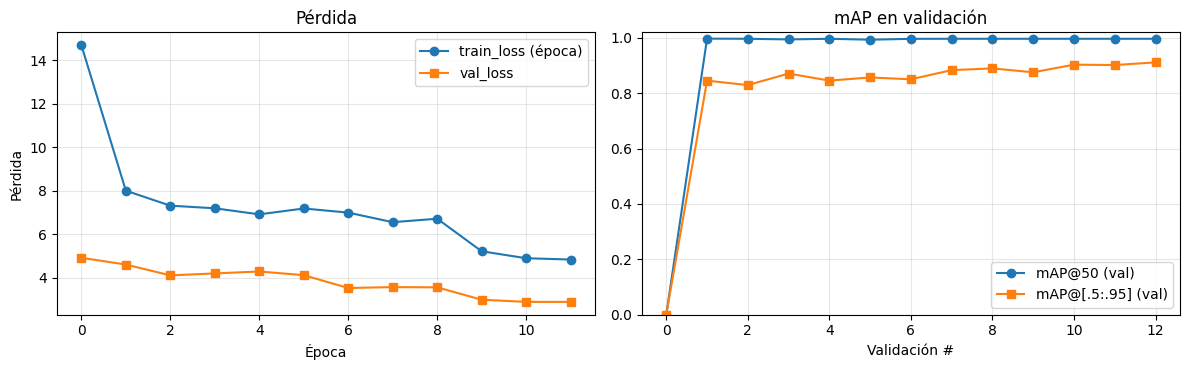

Épocas con train_loss: 12 | validaciones: 13
Última validación: mAP@50=0.997  mAP=0.911


In [14]:
# Curvas por época leídas del log de entrenamiento (TAO imprime las métricas en la barra de progreso)
texto = open("logs/entrenamiento_dino_v1.log", errors="ignore").read().replace("\r", "\n")
tr_ep, va_ep = {}, {}
for m in re.finditer(r"Epoch (\d+):[^\n]*?train_loss_epoch=([0-9.]+)", texto): tr_ep[int(m.group(1))] = float(m.group(2))
for m in re.finditer(r"Epoch (\d+):[^\n]*?val_loss=([0-9.]+)", texto): va_ep[int(m.group(1))] = float(m.group(2))
map50 = [float(x) for x in re.findall(r"Validation mAP50 : ([0-9.]+)", texto)]
mapall = [float(x) for x in re.findall(r"Validation mAP : ([0-9.]+)", texto)]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
if tr_ep: ax[0].plot(list(tr_ep), list(tr_ep.values()), "o-", label="train_loss (época)")
if va_ep: ax[0].plot(list(va_ep), list(va_ep.values()), "s-", label="val_loss")
ax[0].set_xlabel("Época"); ax[0].set_ylabel("Pérdida"); ax[0].set_title("Pérdida"); ax[0].legend(); ax[0].grid(alpha=.3)
if map50: ax[1].plot(range(len(map50)), map50, "o-", label="mAP@50 (val)")
if mapall: ax[1].plot(range(len(mapall)), mapall, "s-", label="mAP@[.5:.95] (val)")
ax[1].set_xlabel("Validación #"); ax[1].set_ylim(0, 1.02); ax[1].set_title("mAP en validación"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("logs/curvas_entrenamiento.png", dpi=120); plt.show()
print("Épocas con train_loss:", len(tr_ep), "| validaciones:", len(map50))
if map50: print(f"Última validación: mAP@50={map50[-1]:.3f}  mAP={mapall[-1]:.3f}")

<a id="6"></a>
## 6. Evaluación con el conjunto de prueba
Evaluamos con imágenes **reservadas** que el modelo nunca vio. Métrica: **mAP** (precisión promedio, protocolo COCO).

**¿Cómo se calcula?** Para cada clase se ordenan las detecciones por confianza. Una detección es correcta si su caja se traslapa con la real con un IoU ≥ 0.5 (**mAP@50**) o, promediando umbrales de 0.50 a 0.95, para **mAP@[.5:.95]**. Con eso se arma la curva precisión-recall; el área bajo la curva es el AP de la clase, y el mAP es el promedio de todas las clases.

In [15]:
# Spec de evaluación/inferencia = spec de entrenamiento + datos de prueba e inferencia
# (TAO 5.5 no permite crear estas secciones desde la línea de comandos porque valen None)
open("specs/clases.txt", "w").write("\n".join(CLASES) + "\n")
TEST_IMG = f"{CONT}/datos/final/test/images"; TEST_JSON = f"{CONT}/datos/final/test/annotations.json"
bloque = (f"  test_data_sources:\n    image_dir: {TEST_IMG}\n    json_file: {TEST_JSON}\n"
          f"  infer_data_sources:\n    image_dir: {TEST_IMG}\n    classmap: {CONT}/specs/clases.txt\n")
txt = open(SPEC).read().replace("  workers: 4", "  workers: 0")   # igual que en el entrenamiento (evita el fallo del DataLoader)
EVAL_SPEC = f"{HOST}/specs/eval.yaml"
open(EVAL_SPEC, "w").write(txt.replace("  num_classes:", bloque + "  num_classes:", 1))
print(open(EVAL_SPEC).read().split("augmentation")[0])

ckpts = sorted(glob.glob(f"{RES}/train/model_epoch_*.pth"))
CKPT = ckpts[-1]
print("Checkpoint a evaluar:", CKPT)
corriendo = "dino_v1" in subprocess.getoutput("docker ps --format '{{.Names}}'")
if corriendo: print("⚠️  El entrenamiento SIGUE corriendo: estos resultados son preliminares. Repitan esta sección al terminar.")
!tao model dino evaluate -e {a_cont(EVAL_SPEC)} \
    evaluate.checkpoint={a_cont(CKPT)} \
    results_dir={CONT}/resultados/dino_v1 > logs/evaluacion_dino_v1.log 2>&1
!grep -aE "Average Precision|mAP|Execution status|Error" logs/evaluacion_dino_v1.log | head -20

# Caja Clara - DINO (TAO 5.5) - ajustado a Tesla T4 16GB
# Basado en la config por defecto de nvidia_tao_pytorch.cv.dino (TAO 5.5.0)
results_dir: /workspace/caja-clara/resultados/dino_v1
wandb:
  enable: false
model:
  backbone: resnet_50
  train_backbone: true
  num_feature_levels: 4
  num_queries: 300
  num_select: 100
  dec_layers: 6
  enc_layers: 6
  dropout_ratio: 0.0
dataset:
  train_data_sources:
    - image_dir: /workspace/caja-clara/datos/final/train/images
      json_file: /workspace/caja-clara/datos/final/train/annotations.json
  val_data_sources:
    - image_dir: /workspace/caja-clara/datos/final/val/images
      json_file: /workspace/caja-clara/datos/final/val/annotations.json
  test_data_sources:
    image_dir: /workspace/caja-clara/datos/final/test/images
    json_file: /workspace/caja-clara/datos/final/test/annotations.json
  infer_data_sources:
    image_dir: /workspace/caja-clara/datos/final/test/images
    classmap: /workspace/caja-clara/specs/clases.txt
  num_classe

**Comparación con el modelo base.** El DINO preentrenado en COCO **no puede evaluarse directamente** en nuestras clases: COCO tiene "botella", pero no distingue *Coca-Cola*, *Gansito* o *Chokis*. Por eso la comparación se hace contra la línea base disponible (detección genérica de COCO) y se explica el motivo, como permite la sección 13 de las bases.

<a id="7"></a>
## 7. Inferencia: aciertos y errores
Corremos el modelo sobre imágenes de prueba y mostramos las cajas que predice. Las bases piden **ejemplos de aciertos y errores**.

In [16]:
!tao model dino inference -e {a_cont(EVAL_SPEC)} \
    inference.checkpoint={a_cont(CKPT)} \
    inference.conf_threshold=0.5 \
    results_dir={CONT}/resultados/dino_v1 > logs/inferencia_dino_v1.log 2>&1
!grep -aiE "Error|Exception|Execution status" logs/inferencia_dino_v1.log | head -10

[2026-11-20 01:33:37,242 - TAO Toolkit - root - WARNING] [Error]: HTTPSConnectionPool(host='api.tao.ngc.nvidia.com', port=443): Max retries exceeded with url: /api/v1/metrics (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x7efd1b7aebc0>: Failed to establish a new connection: [Errno -3] Temporary failure in name resolution'))
[2026-11-20 01:33:37,242 - TAO Toolkit - root - INFO] Execution status: PASS


106 imágenes con predicciones


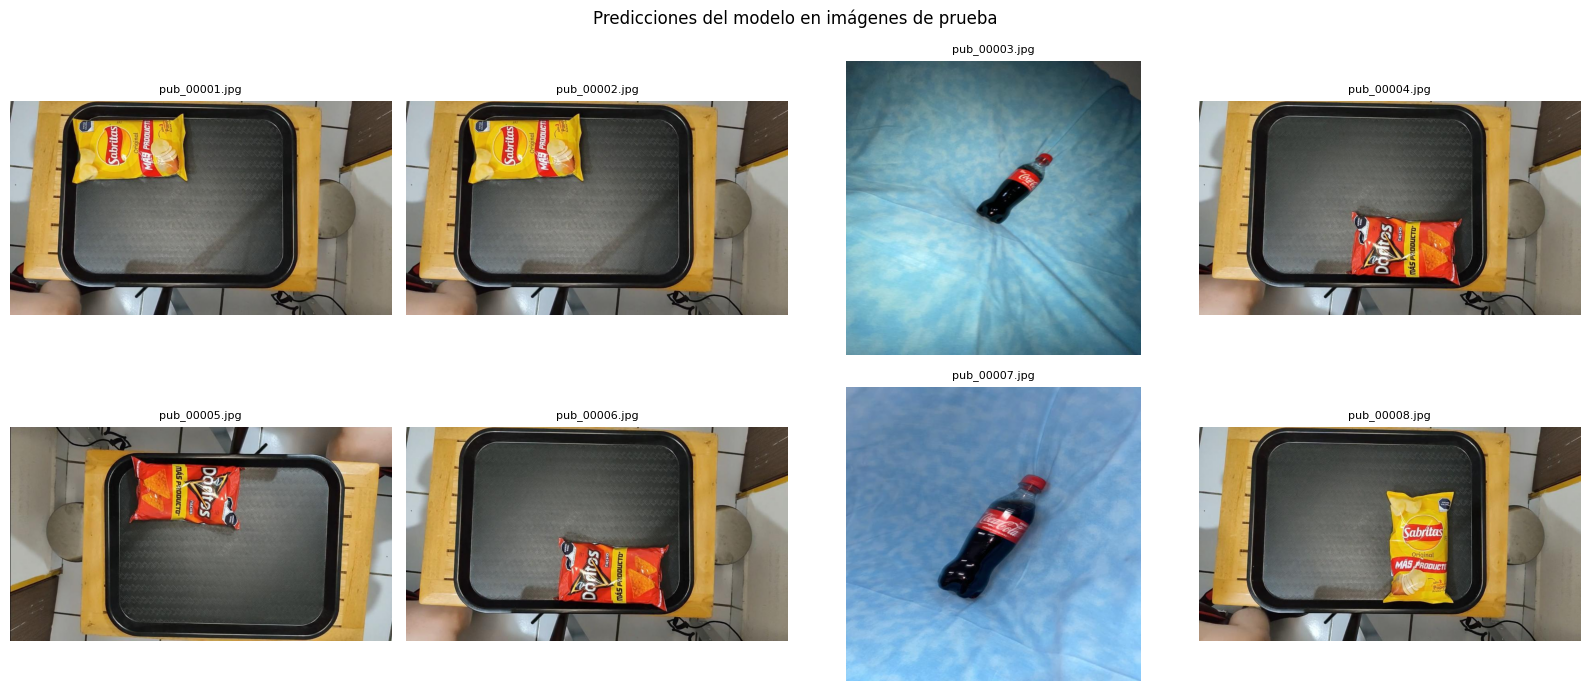

In [17]:
anotadas = sorted(glob.glob(f"{RES}/inference/**/*.jpg", recursive=True) + glob.glob(f"{RES}/inference/**/*.png", recursive=True))
anotadas = [p for p in anotadas if "annotated" in p or "images" in p]
print(len(anotadas), "imágenes con predicciones")
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, p in zip(axs.ravel(), anotadas[:8]):
    ax.imshow(Image.open(p)); ax.set_title(os.path.basename(p), fontsize=8); ax.axis("off")
plt.suptitle("Predicciones del modelo en imágenes de prueba"); plt.tight_layout(); plt.show()

**Ejercicio del equipo:** en las imágenes anteriores, anoten 3 aciertos y 3 errores (producto confundido, producto no detectado o caja de más) y la causa probable: reflejos, productos encimados, luz o ángulo. Esa lista va a la sección de evidencias.

<a id="8"></a>
## 8. Exportación a ONNX y optimización con TensorRT
- **ONNX**: formato portable para desplegar el modelo.
- **TensorRT**: optimiza el modelo para la GPU (FP16) y reduce la latencia.

> El motor de TensorRT depende de la GPU donde se construye. Aquí lo construimos en la T4 para medir la mejora; para la demo se vuelve a construir en la laptop (RTX 2060) a partir del mismo ONNX.

In [18]:
ONNX = f"{RES}/export/dino_caja_clara.onnx"
os.makedirs(f"{RES}/export", exist_ok=True)
!tao model dino export -e {a_cont(SPEC)} \
    export.checkpoint={a_cont(CKPT)} export.onnx_file={a_cont(ONNX)} \
    export.input_width=640 export.input_height=640 export.batch_size=1 2>&1 | tail -3
print(os.path.exists(ONNX) and f"ONNX listo: {os.path.getsize(ONNX)/1e6:.1f} MB")

[2026-11-20 01:34:22,682 - TAO Toolkit - root - WARNING] [Error]: HTTPSConnectionPool(host='api.tao.ngc.nvidia.com', port=443): Max retries exceeded with url: /api/v1/metrics (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x7f6c60baeb90>: Failed to establish a new connection: [Errno -3] Temporary failure in name resolution'))
[2026-11-20 01:34:22,682 - TAO Toolkit - root - WARNING] Execution status: FAIL
2026-11-20 01:34:23,594 [TAO Toolkit] [INFO] nvidia_tao_cli.components.docker_handler.docker_handler 363: Stopping container.
ONNX listo: 210.9 MB


In [ ]:
ENGINE = f"{RES}/export/dino_caja_clara_fp16_t4.engine"
!tao deploy dino gen_trt_engine -e {a_cont(SPEC)} \
    gen_trt_engine.onnx_file={a_cont(ONNX)} gen_trt_engine.trt_engine={a_cont(ENGINE)} \
    gen_trt_engine.input_width=640 gen_trt_engine.input_height=640 \
    gen_trt_engine.tensorrt.data_type=FP16 gen_trt_engine.batch_size=1 \
    gen_trt_engine.tensorrt.min_batch_size=1 gen_trt_engine.tensorrt.opt_batch_size=1 gen_trt_engine.tensorrt.max_batch_size=1 \
    results_dir={CONT}/resultados/dino_v1 > logs/trt_engine_v1.log 2>&1
!grep -aiE "Error|Execution status|engine" logs/trt_engine_v1.log | tail -5

### 8.1 Evaluación con el motor TensorRT (misma prueba)
Comparamos la exactitud y la velocidad del modelo en PyTorch contra TensorRT FP16. Anoten el tiempo por imagen que reporta cada uno.

In [ ]:
!tao deploy dino evaluate -e {a_cont(EVAL_SPEC)} \
    evaluate.trt_engine={a_cont(ENGINE)} \
    results_dir={CONT}/resultados/dino_v1 > logs/evaluacion_trt_v1.log 2>&1
!grep -aE "Average Precision|mAP|FPS|latency|Execution status|Error" logs/evaluacion_trt_v1.log | head -15

<a id="9"></a>
## 9. Artefactos y verificación
La app mostrará el **hash** de los pesos que usa, para que el jurado verifique que son los entrenados aquí (bases, sección 6c).

In [ ]:
os.makedirs("modelos", exist_ok=True)
artefactos = {"checkpoint": CKPT, "onnx": ONNX, "engine_t4": ENGINE}
reg = {}
for k, p in artefactos.items():
    if os.path.exists(p):
        reg[k] = {"archivo": os.path.relpath(p, HOST), "MB": round(os.path.getsize(p)/1e6, 1),
                  "sha256": hashlib.sha256(open(p, "rb").read()).hexdigest()}
reg["modelo_base"] = "nvidia/tao/pretrained_dino_coco:dino_resnet_50_trainable_v1.0"
reg["gpu"] = subprocess.getoutput("nvidia-smi --query-gpu=name --format=csv,noheader")
reg["fecha_utc"] = f"{datetime.datetime.utcnow():%Y-%m-%d %H:%M}"
json.dump(reg, open("modelos/registro_modelo_vision.json", "w"), indent=2)
print(json.dumps(reg, indent=2))
bitacora("Artefactos del detector registrados")

In [ ]:
# Empaquetar para descargar a la laptop (pesos + logs + specs + distribución)
!tar czf entrega_vision_v1.tgz modelos/registro_modelo_vision.json specs/ logs/ datos/FUENTES.txt resultados/dino_v1/export/*.onnx 2>/dev/null
!ls -lh entrega_vision_v1.tgz

<a id="10"></a>
## 10. Resultados, limitaciones y declaración de IA
### Resultados (llenar con los números obtenidos, sin redondear a favor)
| Métrica | Valor |
|---|---|
| mAP@50 (prueba) | _ |
| mAP@[.5:.95] (prueba) | _ |
| Latencia PyTorch (ms/img) | _ |
| Latencia TensorRT FP16 (ms/img) | _ |

### Limitaciones conocidas
- La v1 usa solo datos públicos con **un producto por imagen**; en la app las fotos traen varios productos juntos. La v2 incorpora fotos propias con mezclas.
- Desbalance de clases (Coca-Cola mucho más frecuente).
- El detector cubre productos empacados de tienda; la comida y los materiales se registran por voz con el asistente.

### Componentes previos
- TAO Toolkit 5.5 y el modelo DINO preentrenado de NGC (NVIDIA).
- Datasets públicos de Roboflow Universe (CC BY 4.0), listados en `datos/FUENTES.txt`.

### Declaración del uso de IA
*"Para la elaboración de este trabajo se utilizó [HERRAMIENTA Y COMPAÑÍA] como apoyo en [ACTIVIDADES]. Quienes firman este trabajo han revisado y editado el contenido, verificado las fuentes y asumen plena responsabilidad por la versión final."*